# 5. Stage 4: Tracker

A tracker changes the question from "is this one detection real?" to "is this sequence of detections real?". That has two effects: detection and false-alarm performance can be traded, and estimates improve through filtering.

## Pd and Pfa: M-of-N confirmation

With per-look detection probability $p$, confirmation by $M$ detections in $N$ looks has

$$P_{\text{confirm}} = \sum_{k=M}^{N}\binom{N}{k}p^k(1-p)^{N-k}$$

Because false alarms rarely line up in consecutive scans, the per-look threshold can be **lowered**. The per-look $P_{fa}$ rises, but the false-**track** rate stays acceptable:

$$\text{False tracks per hour} = P_{fa}N_{cells}\cdot P\left[\geq M-1\text{ of }N-1\text{ hits in the gate}\right]\cdot \frac{3600}{T}$$

The lower threshold is worth real SNR. This is the **tracker gain**, and its price is the delay to confirm.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Single look: Pd 0.944 at Pfa 6.45e-11, 36 false alarms per hour
With tracker: per-look Pfa 3.16e-05, per-look Pd 0.980, confirmed 0.998, 0.57 false tracks per hour
Tracker gain 6.6 dB. Confirmation takes about 3.1 scans (3.1 s). This is the price of the gain.


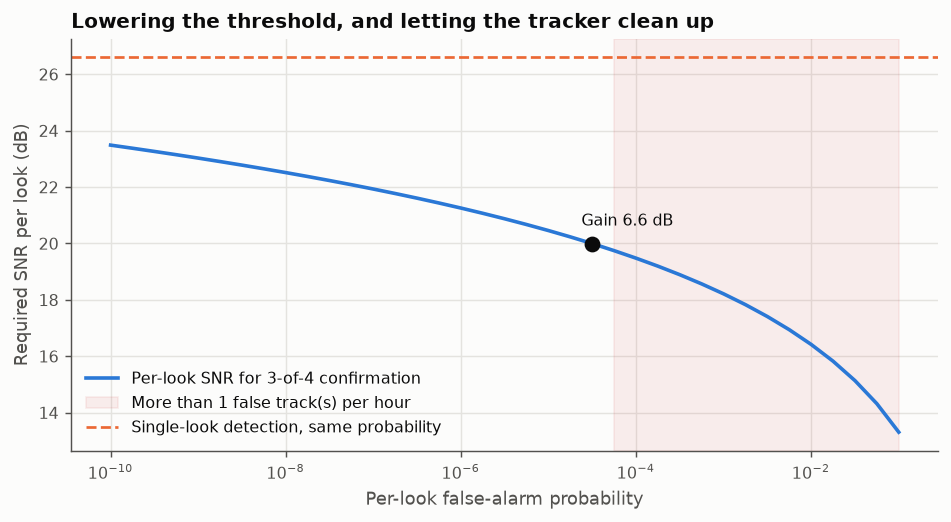

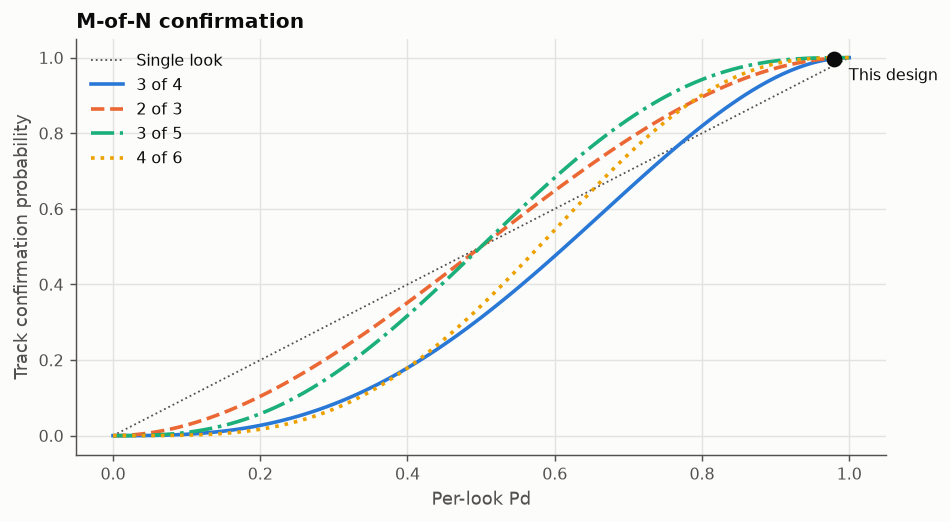

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
# Run from the notebooks folder, or from the project root.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

from bistatic_lb import Scenario, run_link_budget, plots

from bistatic_lb.tracker.initiation import confirm_probability, scans_to_confirm

s = Scenario.from_yaml(Path("../scenarios/dvbt_uhf.yaml" if Path.cwd().name == "notebooks" else "scenarios/dvbt_uhf.yaml"))
r = run_link_budget(s)
t = r.tracker
print(f"Single look: Pd {t.single_look_pd:.3f} at Pfa {t.single_look_pfa:.2e}, {t.single_look_false_alarms_per_hour:.3g} false alarms per hour")
print(f"With tracker: per-look Pfa {t.trade.best_pfa:.2e}, per-look Pd {t.relaxed_pd:.3f}, confirmed {t.confirm_probability_at_relaxed_threshold:.3f}, {t.false_tracks_per_hour:.3g} false tracks per hour")
print(f"Tracker gain {t.trade.gain_db:.1f} dB. {t.latency_note}")
plots.threshold_trade_snr(r); plots.confirmation_curves(r); plt.show()


### Check: the Markov chain against simulation

Sliding-window M-of-N is a Markov chain on the last $N$ outcomes, which gives the mean time to confirm.

In [2]:
rng = np.random.default_rng(5)
print(f"{'p':>5s} {'M of N':>7s} {'Chain (scans)':>14s} {'Simulated':>10s}")
for p, m, n in ((0.5, 2, 3), (0.6, 3, 4), (0.8, 3, 5), (0.9, 4, 6)):
    trials = rng.random((30_000, 300)) < p
    counts = np.apply_along_axis(lambda a: np.convolve(a, np.ones(n), "full")[:len(a)], 1, trials)
    first = np.argmax(counts >= m, axis=1) + 1
    print(f"{p:5.2f} {f'{m} of {n}':>7s} {scans_to_confirm(p, m, n)[0]:14.3f} {first.mean():10.3f}")


    p  M of N  Chain (scans)  Simulated


 0.50  2 of 3          4.667      4.673


 0.60  3 of 4          6.271      6.210


 0.80  3 of 5          3.797      3.802


 0.90  4 of 6          4.460      4.465


## Accuracy: Kalman filter and its bound

The filter tracks bi-static range and range rate, with white-noise acceleration:

$$F = \begin{bmatrix}1 & T\\0 & 1\end{bmatrix},\quad Q = \sigma_a^2\begin{bmatrix}T^4/4 & T^3/2\\T^3/2 & T^2\end{bmatrix}$$

The steady state comes from the Riccati recursion. The **posterior Cramer-Rao bound** adds the effect of missed detections and clutter through an information-reduction factor $q \leq P_d$ (Hernandez, Farina and Ristic, 2006):

$$J_{k+1} = \left(Q + FJ_k^{-1}F^T\right)^{-1} + q\,H^TR^{-1}H$$

The factor $q$ is computed by Monte Carlo as the expected squared score of the association-marginalized likelihood.

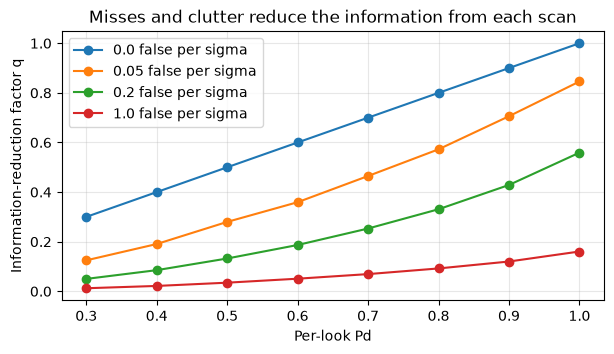

In [3]:
from bistatic_lb.tracker.bounds import information_reduction_factor
pd = np.linspace(0.3, 1.0, 8)
fig, ax = plt.subplots(figsize=(7, 3.5))
for density in (0.0, 0.05, 0.2, 1.0):
    ax.plot(pd, [information_reduction_factor(p, density, trials=4000) for p in pd], marker="o", label=f"{density} false per sigma")
ax.set(xlabel="Per-look Pd", ylabel="Information-reduction factor q", title="Misses and clutter reduce the information from each scan"); ax.grid(alpha=0.3); ax.legend(); plt.show()


## Simulation

Detections are drawn from the link budget along a straight flight path. Two filters run:

- A Kalman filter on range and range rate, and
- An extended Kalman filter to Cartesian position, using range, range rate and azimuth.

Association is nearest-neighbour or probabilistic data association (PDA).

Continuity 100.0%, 0 of 200 runs lost, seed 1


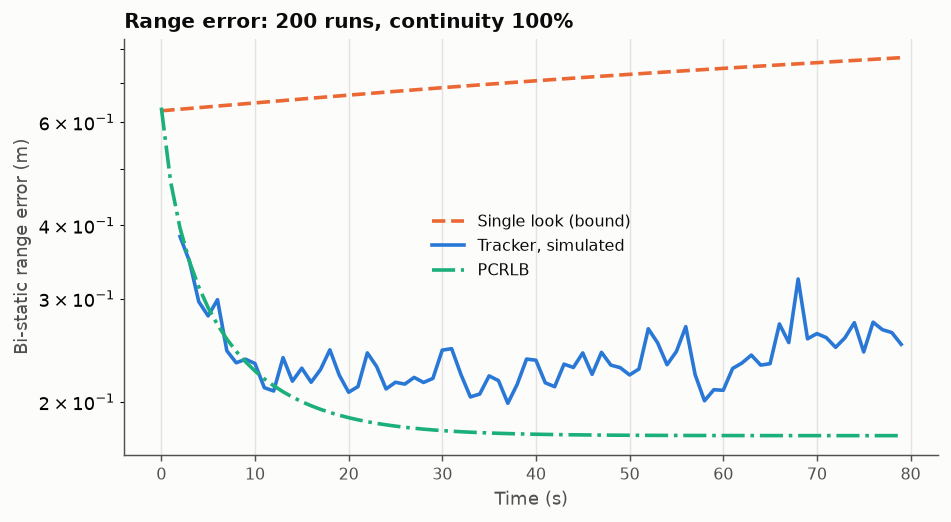

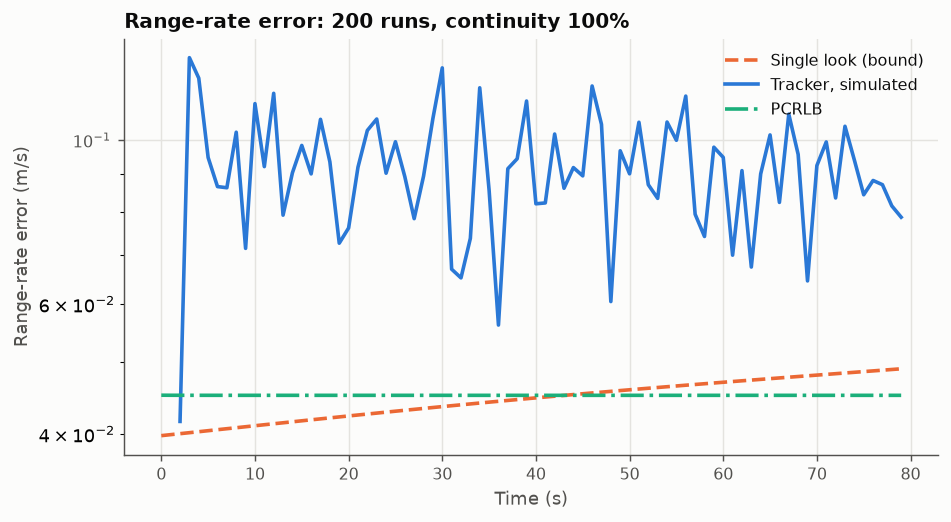

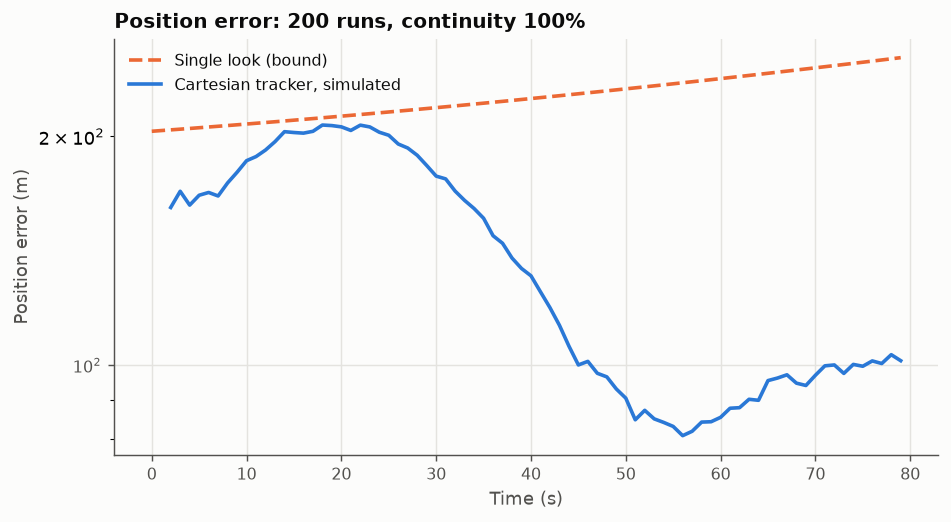

In [4]:
from bistatic_lb.tracker import run_tracker_monte_carlo
s.monte_carlo.runs = 200; s.monte_carlo.scans = 80
r = run_link_budget(s)
mc = run_tracker_monte_carlo(r.analyzer, r.tracker.trade.best_pfa)
print(f"Continuity {mc.continuity:.1%}, {mc.lost_runs} of {mc.runs} runs lost, seed {mc.seed}")
plots.tracker_rmse(mc, "range"); plots.tracker_rmse(mc, "rate"); plots.tracker_rmse(mc, "position"); plt.show()


Reading the charts:

- The simulated filter stays above the PCRLB, as it must. A small gap is expected with PDA in clutter.
- Range error falls well under the single-look value because the very accurate Doppler measurement integrates into range.
- Cartesian position improves greatly, because azimuth is the weakest measurement and has the most to gain.
- These errors reflect noise only. Timing errors, drift and target extent would put a floor under them in a real system.

## A weaker target, and the association method

As the target weakens, Pd falls and measurements get noisier, so both track continuity and accuracy suffer. The per-look Pfa here is 1e-3, deliberately high.

In [5]:
print(f"{'Association':14s}{'RCS dBsm':>10s}{'SINR dB':>9s}{'Pd':>7s}{'Continuity':>12s}{'Final range RMSE (m)':>22s}")
for assoc in ("pda", "nearest"):
    for rcs in (10.0, 0.0, -5.0, -10.0, -15.0):
        t = s.with_value("tracker.association", assoc).with_value("target.rcs_dbsm", rcs)
        x = run_link_budget(t)
        m = run_tracker_monte_carlo(x.analyzer, 1e-3)
        print(f"{assoc:14s}{rcs:10.0f}{x.link.sinr_db:9.1f}{np.mean(m.per_scan_pd):7.2f}{m.continuity:12.1%}{np.mean(m.rmse_range_m[-15:]):22.2f}")


Association     RCS dBsm  SINR dB     Pd  Continuity  Final range RMSE (m)


pda                   10     27.8   0.98      100.0%                  0.24


pda                    0     17.8   0.85       98.5%                  0.93


pda                   -5     12.8   0.62       69.0%                  2.28


pda                  -10      7.8   0.27        2.1%                   nan


pda                  -15      2.8   0.05       14.3%                   nan


nearest               10     27.8   0.98      100.0%                  0.24


nearest                0     17.8   0.85       98.5%                  0.93


nearest               -5     12.8   0.62       68.5%                  2.39


nearest              -10      7.8   0.27        2.6%                   nan


nearest              -15      2.8   0.05        0.0%                905.60


False alarms play little part here. The gate is usually smaller than one range-Doppler cell, because accuracy is much finer than resolution, so few false alarms fall inside it. That is why the two association methods behave alike in this system, until the target gets so weak that the gate grows. Pd and accuracy set the limit. A track counts as lost after more than N consecutive misses, so continuity collapses once Pd falls to about 0.3. The RMSE column covers only the runs that kept their track, or all runs if none did, so read it together with continuity: a low RMSE at 1% continuity describes the few survivors.

## Starting a track from a detection

The simulation above does not hand the tracker the truth. Each track starts at the target's first detection, from that one measurement, and must collect M hits in N scans before it counts. A tentative track that sees nothing for N scans is dropped. The simulated time to confirm can therefore be checked against the Markov-chain prediction.

The Cartesian filter starts with the velocity unknown. Range and range rate are far sharper than the azimuth, so a linearized (extended Kalman) update is inconsistent here and can diverge; the filter uses an unscented update instead. When the array cannot measure elevation, the fix also needs an assumed altitude, and each run offsets it by a draw from the stated altitude uncertainty.

Below: position error for tracks started on the truth (best case) and from a detection, then the same with a 2 m/s² turn (what the filter is tuned for) and a 10 m/s² turn starting halfway through.

Started on the truth             confirmed 200/200, scans to confirm 1.00 (predicted 3.06), continuity 100%


Started from a detection         confirmed 200/200, scans to confirm 3.04 (predicted 3.06), continuity 100%


From a detection, 2 m/s2 turn    confirmed 200/200, scans to confirm 3.06 (predicted 3.06), continuity 100%


From a detection, 10 m/s2 turn   confirmed 200/200, scans to confirm 3.06 (predicted 3.06), continuity 0%


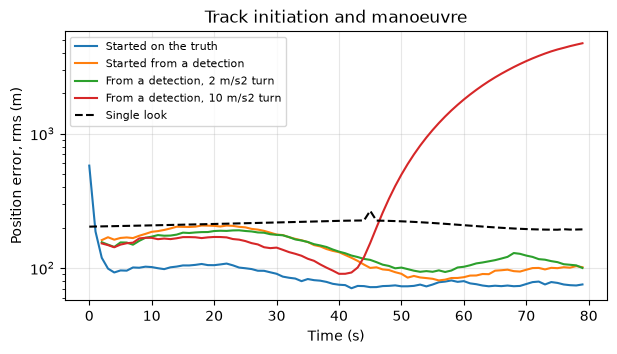

In [6]:
cases = {
    "Started on the truth": s.with_value("monte_carlo.initiation", "on_truth"),
    "Started from a detection": s,
    "From a detection, 2 m/s2 turn": s.with_value("monte_carlo.manoeuvre_accel_m_s2", 2.0),
    "From a detection, 10 m/s2 turn": s.with_value("monte_carlo.manoeuvre_accel_m_s2", 10.0),
}
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, case in cases.items():
    x = run_link_budget(case)
    m = run_tracker_monte_carlo(x.analyzer, x.tracker.trade.best_pfa)
    ax.semilogy(m.time_s, m.rmse_position_m, label=name)
    print(f"{name:32s} confirmed {m.confirmed_runs}/{m.runs}, scans to confirm {m.mean_scans_to_confirm:.2f} "
          f"(predicted {x.tracker.mean_scans_to_confirm:.2f}), continuity {m.continuity:.0%}")
ax.semilogy(m.time_s, m.single_look_position_m, "k--", label="Single look")
ax.set(xlabel="Time (s)", ylabel="Position error, rms (m)", title="Track initiation and manoeuvre"); ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()